<a href="https://colab.research.google.com/github/dsouzabrandon02-ops/CSL701-14_Machine-Learning-Lab/blob/main/Eperiments/_ml_experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10

Student Name : Brandon .B. Dsouza


Batch : CS01


Roll Number : CS14



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import urllib.request
import os

# Download the dataset directly from a working public mirror
url = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'
csv_path = 'Mall_Customers.csv'
if not os.path.exists(csv_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, csv_path)

# Load dataset
df = pd.read_csv(csv_path)
display(df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:
# Select target features
X_raw = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Scale features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Display summary of scaled features
print("Scaled Features Shape:", X_scaled.shape)
print("Mean after scaling (should be ~0):", X_scaled.mean(axis=0))
print("Std after scaling (should be ~1):", X_scaled.std(axis=0))

Scaled Features Shape: (200, 2)
Mean after scaling (should be ~0): [-2.13162821e-16 -1.46549439e-16]
Std after scaling (should be ~1): [1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

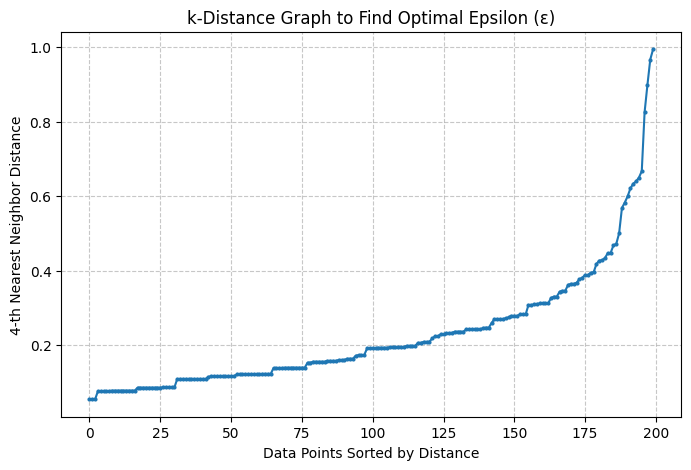

Selected optimal hyper-parameters: min_samples = 4, epsilon = 0.35


In [ ]:
# A typical choice for min_samples is 2 * dimensionality of the data
min_samples = 4

# Compute Nearest Neighbors
# We use k = min_samples to find the distance to the k-th nearest neighbor
neigh = NearestNeighbors(n_neighbors=min_samples)
nbrs = neigh.fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

# Sort distance to the k-th nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot the k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances, marker='o', linestyle='-', markersize=2)
plt.title('k-Distance Graph to Find Optimal Epsilon (ε)')
plt.xlabel('Data Points Sorted by Distance')
plt.ylabel(f'{min_samples}-th Nearest Neighbor Distance')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# We will select an epsilon around the elbow point of this graph
# Let's inspect and use a value of around 0.3 to 0.4 based on the scaled data graph.
optimal_epsilon = 0.35
print(f"Selected optimal hyper-parameters: min_samples = {min_samples}, epsilon = {optimal_epsilon}")

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:
# Instantiate and fit DBSCAN
dbscan = DBSCAN(eps=0.35, min_samples=4)
dbscan.fit(X_scaled)

# Extract labels
labels = dbscan.labels_
print("Unique labels assigned:", np.unique(labels))

Unique labels assigned: [-1  0  1  2  3  4  5  6]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:
# Calculate number of clusters (excluding noise points if present)
unique_labels = set(labels)
n_clusters_ = len(unique_labels) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f'Estimated number of clusters: {n_clusters_}')
print(f'Estimated number of noise points: {n_noise_}')

# Calculate Silhouette Score (only defined if there is more than 1 cluster)
if n_clusters_ > 1:
    # Filter out noise points for a clean silhouette computation of clustered points if desired,
    # or compute on entire dataset including noise as separate labels.
    score = silhouette_score(X_scaled, labels)
    print(f'Silhouette Coefficient: {score:.3f}')
else:
    print('Silhouette Score could not be calculated (needs >= 2 clusters).')

Estimated number of clusters: 7
Estimated number of noise points: 16
Silhouette Coefficient: 0.426


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Profile Statistics (Means):


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
-1,33.750000,93.250000,65.812500
0,24.411765,25.235294,76.352941
1,48.750000,24.583333,9.583333
2,36.714286,22.428571,34.428571
3,42.797753,55.022472,48.325843
4,32.812500,80.500000,82.562500
5,41.217391,80.956522,12.782609
6,41.500000,101.000000,24.000000


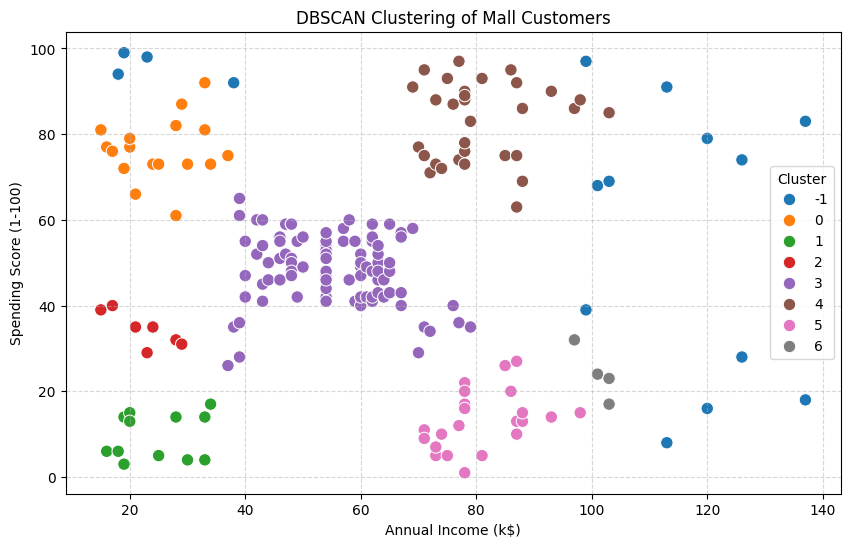

In [ ]:
# Append cluster labels back to the original dataset
df['Cluster'] = labels

# Calculate mean statistics per cluster
cluster_stats = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean()
print("Cluster Profile Statistics (Means):")
display(cluster_stats)

# Visualize final clusters using seaborn
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    data=df,
    legend='full',
    s=80
)
plt.title('DBSCAN Clustering of Mall Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.